<a href="https://colab.research.google.com/github/lokreylatika/Customer-Churn-Prediction-System/blob/main/Customer_Churn_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q kagglehub gradio

In [3]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download("blastchar/telco-customer-churn")

csv_file = None

for file in os.listdir(path):
    if file.endswith(".csv") and "Telco-Customer-Churn" in file:
        csv_file = os.path.join(path, file)
        break

if csv_file is None:
    raise FileNotFoundError(f"Dataset CSV not found in: {path}")

df = pd.read_csv(csv_file)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

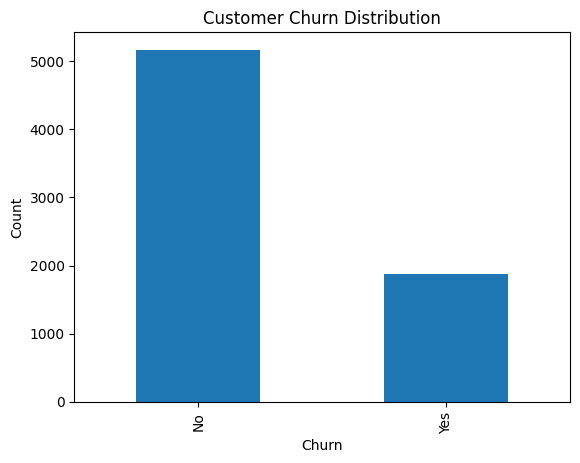

Features: ['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
Number of features: 17


In [4]:
import matplotlib.pyplot as plt

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

df["Churn"].value_counts().plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.show()

# Remove unnecessary columns
df.drop(
    columns=["customerID", "gender", "PhoneService"],
    inplace=True
)

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features:", X.columns.tolist())
print("Number of features:", X.shape[1])

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_cols
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        )
    ]
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 5634
Testing rows: 1409


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

estimators = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

trained_models = {}

for name, estimator in estimators.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

print("All three models trained successfully!")

All three models trained successfully!


In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, y_pred) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(y_test, y_pred, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, y_pred, zero_division=0) * 100, 2
        ),
        "F1-Score (%)": round(
            f1_score(y_test, y_pred, zero_division=0) * 100, 2
        )
    })

results_df = pd.DataFrame(results)

display(results_df)

best_name = results_df.loc[
    results_df["F1-Score (%)"].idxmax(), "Model"
]

best_model = trained_models[best_name]

print("Best model based on F1-score:", best_name)

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,80.55,65.72,55.88,60.40
1,Decision Tree,72.18,47.76,51.34,49.48
2,Random Forest,78.21,61.13,49.20,54.52


Best model based on F1-score: Logistic Regression


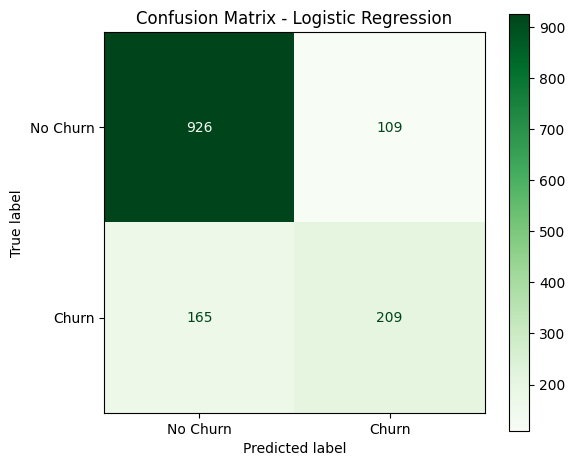

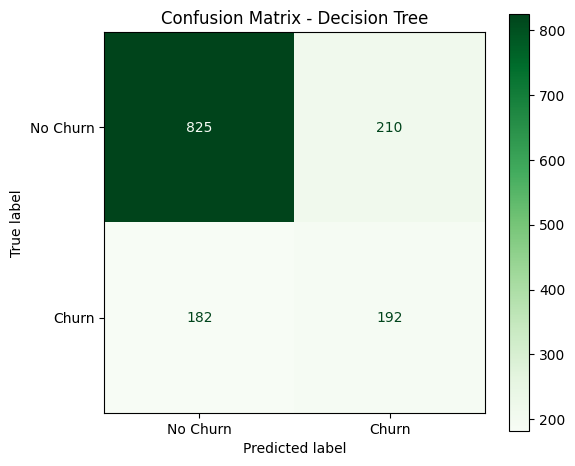

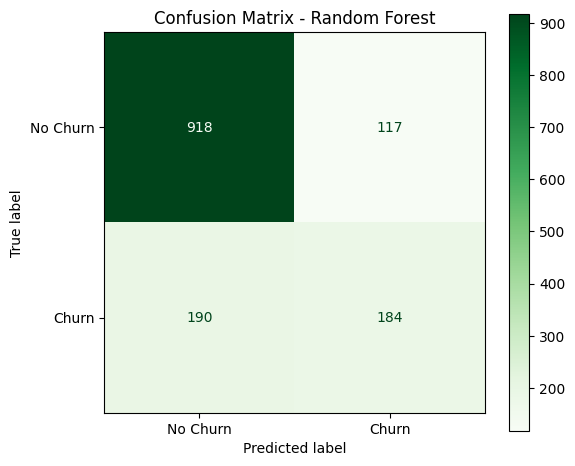

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    disp.plot(
        ax=ax,
        cmap="Greens",
        values_format="d",
        colorbar=True
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

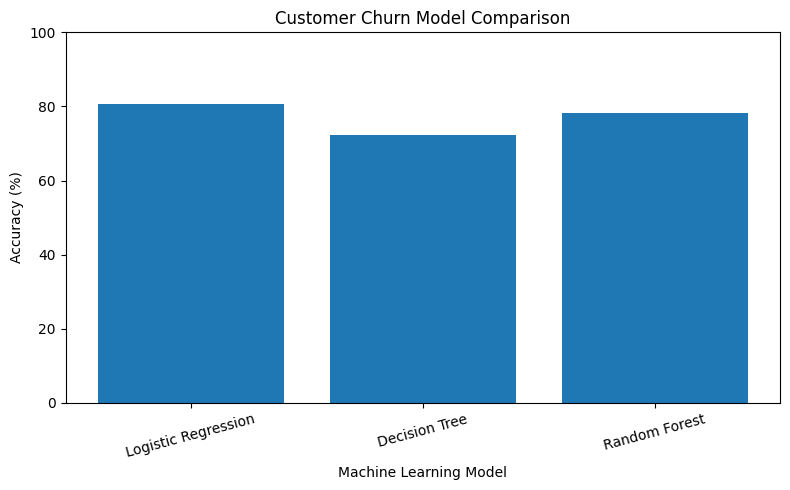

In [9]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy (%)"]
)

plt.title("Customer Churn Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
import gradio as gr

def predict_churn(
    senior, partner, dependents, tenure,
    multiple_lines, internet_service, online_security,
    online_backup, device_protection, tech_support,
    streaming_tv, streaming_movies, contract,
    paperless_billing, payment_method,
    monthly_charges, total_charges
):
    customer = {
        "SeniorCitizen": int(senior),
        "Partner": partner,
        "Dependents": dependents,
        "tenure": float(tenure),
        "MultipleLines": multiple_lines,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": float(monthly_charges),
        "TotalCharges": float(total_charges)
    }

    customer_df = pd.DataFrame(
        [customer],
        columns=X.columns
    )

    prediction = best_model.predict(customer_df)[0]
    probability = best_model.predict_proba(customer_df)[0][1] * 100

    if prediction == 1:
        status = "Customer Likely To Churn"
    else:
        status = "Customer Likely To Stay"

    return (
        f"{status}\n"
        f"Churn Probability: {probability:.2f}%\n"
        f"Model Used: {best_name}"
    )


yes_no = ["No", "Yes"]

demo = gr.Interface(
    fn=predict_churn,
    inputs=[
        gr.Dropdown([0, 1], value=0, label="Senior Citizen (0=No, 1=Yes)"),
        gr.Dropdown(yes_no, value="No", label="Partner"),
        gr.Dropdown(yes_no, value="No", label="Dependents"),
        gr.Slider(0, 72, value=12, step=1, label="Tenure (Months)"),
        gr.Dropdown(
            ["No", "Yes", "No phone service"],
            value="No",
            label="Multiple Lines"
        ),
        gr.Dropdown(
            ["DSL", "Fiber optic", "No"],
            value="DSL",
            label="Internet Service"
        ),
        gr.Dropdown(
            ["No", "Yes", "No internet service"],
            value="No",
            label="Online Security"
        ),
        gr.Dropdown(
            ["No", "Yes", "No internet service"],
            value="No",
            label="Online Backup"
        ),
        gr.Dropdown(
            ["No", "Yes", "No internet service"],
            value="No",
            label="Device Protection"
        ),
        gr.Dropdown(
            ["No", "Yes", "No internet service"],
            value="No",
            label="Tech Support"
        ),
        gr.Dropdown(
            ["No", "Yes", "No internet service"],
            value="No",
            label="Streaming TV"
        ),
        gr.Dropdown(
            ["No", "Yes", "No internet service"],
            value="No",
            label="Streaming Movies"
        ),
        gr.Dropdown(
            ["Month-to-month", "One year", "Two year"],
            value="Month-to-month",
            label="Contract"
        ),
        gr.Dropdown(yes_no, value="Yes", label="Paperless Billing"),
        gr.Dropdown(
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ],
            value="Electronic check",
            label="Payment Method"
        ),
        gr.Number(value=70.0, label="Monthly Charges"),
        gr.Number(value=800.0, label="Total Charges")
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="AI-Powered Customer Churn Prediction",
    description=(
        "Enter customer subscription and billing details "
        "to predict whether the customer may churn."
    )
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://6baa84d3b7be4d3390.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
